# 基于Agent轨迹的SFT：模型加载与评估

## 1. 评估配置与依赖
路径和模型名称沿用全量训练 Notebook。评估阶段不需要 `Trainer`、Optimizer、Gradient Checkpointing，也不需要重新读取 634 个原始 Session 文件。

In [1]:
from pathlib import Path
from typing import Any
import json
import random
import math

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForMultimodalLM
from peft import PeftModel

# 与 sft-full-training.ipynb 保持一致
MODEL_ID = "google/gemma-4-E2B-it"
DATA_DIR = Path("./sft-data")
OUTPUT_DIR = Path("./sft-output/gemma4-e2b-lora-full")
ADAPTER_DIR = OUTPUT_DIR / "final_adapter"
MAX_LENGTH = 2048
VAL_JSONL = DATA_DIR / f"validation_tokens_{MAX_LENGTH}.jsonl"
EVAL_OUTPUT_DIR = OUTPUT_DIR / "evaluation"
SEED = 42

# 默认评估全部验证样本；可在调试时设为整数（例如 10）
EVAL_LIMIT = None
GENERATION_COUNT = 3
MAX_NEW_TOKENS = 128

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError("当前未检测到 CUDA GPU，请在 RTX 5090 服务器上运行")
if not ADAPTER_DIR.joinpath("adapter_config.json").exists():
    raise FileNotFoundError(f"未找到保存的 LoRA Adapter: {ADAPTER_DIR}")
if not VAL_JSONL.exists():
    raise FileNotFoundError(f"未找到 Token 级验证数据: {VAL_JSONL}")

print("基础模型:", MODEL_ID)
print("Adapter 路径:", ADAPTER_DIR)
print("验证集路径:", VAL_JSONL)
print("当前工作目录:", Path.cwd())
print("CUDA 可见显卡:", torch.cuda.device_count())

基础模型: google/gemma-4-E2B-it
Adapter 路径: sft-output/gemma4-e2b-lora-full/final_adapter
验证集路径: sft-data/validation_tokens_2048.jsonl
当前工作目录: /home/yousatech/LLMs-from-scratch/agent_post_training
CUDA 可见显卡: 1


## 2. 加载 Tokenizer 与验证数据集
直接读取训练阶段已经生成的 `validation_tokens_2048.jsonl`。该数据集按 Session 与训练集分离，字段为 `input_ids`、`attention_mask`、`labels`；其中 `labels=-100` 的 Prompt 部分不参与 Loss。

In [2]:
# 加载与训练时一致的 Tokenizer
# 如果训练结束后没有单独保存 Tokenizer，可回退到基础模型 Tokenizer
TOKENIZER_SOURCE = (
    str(ADAPTER_DIR)
    if (ADAPTER_DIR / "tokenizer_config.json").exists()
    else MODEL_ID
)
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_SOURCE)
tokenizer.padding_side = "right"

# split="train" 只是给单文件指定 datasets 的返回 split 名称，不会重新划分数据
full_eval_dataset = load_dataset(
    "json",
    data_files=str(VAL_JSONL),
    split="train",
)
eval_dataset = (
    full_eval_dataset
    if EVAL_LIMIT is None
    else full_eval_dataset.select(range(min(EVAL_LIMIT, len(full_eval_dataset))))
)

print("原始验证样本数:", len(full_eval_dataset))
print("本次评估样本数:", len(eval_dataset))
print("Dataset 字段:", eval_dataset.column_names)
print("最长验证序列:", max(len(x) for x in eval_dataset["input_ids"]))

原始验证样本数: 534
本次评估样本数: 534
Dataset 字段: ['input_ids', 'attention_mask', 'labels']
最长验证序列: 2044


## 3. 加载 Gemma 4 E2B 和训练后的 LoRA Adapter
仅加载一份基础模型，通过 `model.disable_adapter()` 临时切换至 **Base Model**，启用 Adapter 时就是 **SFT Model**。两种模型共用相同基础权重、Tokenizer 和验证集，避免重复占用显存。
**注意**：与训练阶段不同，这里不能调用 `get_peft_model()` 初始化新的随机 LoRA；必须从 `final_adapter/` 恢复已训练的权重。

In [3]:
# BF16 基础模型（仅放在可见的 GPU 0）
base_model = AutoModelForMultimodalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.bfloat16,
    device_map={"": 0},
    attn_implementation="sdpa",
    low_cpu_mem_usage=True,
)

# 加载训练产物，不再更新权重
model = PeftModel.from_pretrained(
    base_model,
    str(ADAPTER_DIR),
    is_trainable=False,
)
model.eval()
model.config.use_cache = False   # Loss 评估不使用生成缓存

print("模型类型:", type(model).__name__)
print("当前 Adapter:", model.active_adapter)
print("LoRA 权重路径:", ADAPTER_DIR)
print("可训练参数:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("GPU 显存占用(GiB):", round(torch.cuda.memory_allocated(0) / 1024**3, 2))

Loading weights:   0%|          | 0/2011 [00:00<?, ?it/s]

模型类型: PeftModelForCausalLM
当前 Adapter: default
LoRA 权重路径: sft-output/gemma4-e2b-lora-full/final_adapter
可训练参数: 0
GPU 显存占用(GiB): 9.59


## 4. 在独立验证集上比较 Base / SFT Loss
评估时始终使用训练阶段相同的 Token IDs 和 Completion-only `labels`。一个样本中只有 `labels != -100` 的目标 Token 对应的预测位置计入语言模型 Loss。为避免训练结束后 Jupyter 的 `NotebookProgressCallback` 状态报错，此处**直接使用模型前向传播**而不是 `trainer.evaluate()`。

In [4]:
# 单卡逐样本评估：控制内存占用，不重复分词或 Padding
@torch.inference_mode()
def compare_validation_loss(model, dataset):
    model.eval()
    device = next(model.parameters()).device
    rows = []

    for index, sample in enumerate(tqdm(dataset, desc="Base / SFT 验证")):
        batch = {
            field: torch.tensor([sample[field]], dtype=torch.long, device=device)
            for field in ("input_ids", "attention_mask", "labels")
        }

        # 因果语言模型用位置 t-1 预测位置 t，所以排除 labels 的第 0 位
        target_tokens = int((
            (batch["labels"][:, 1:] != -100)
            & (batch["attention_mask"][:, 1:] == 1)
        ).sum().item())
        if target_tokens == 0:
            continue

        # 不启用 LoRA：基础模型
        with model.disable_adapter():
            base_loss = model(**batch, use_cache=False).loss.float().item()

        # 启用 LoRA：微调模型
        sft_loss = model(**batch, use_cache=False).loss.float().item()

        if not (math.isfinite(base_loss) and math.isfinite(sft_loss)):
            raise ValueError(f"验证样本 {index} 出现无效 Loss")

        rows.append({
            "index": index,
            "seq_len": len(sample["input_ids"]),
            "target_tokens": target_tokens,
            "base_loss": base_loss,
            "sft_loss": sft_loss,
            "improvement": base_loss - sft_loss,
        })

    return pd.DataFrame(rows)


df_eval = compare_validation_loss(model, eval_dataset)
display(df_eval.head())

Base / SFT 验证:   0%|          | 0/534 [00:00<?, ?it/s]

,index,seq_len,target_tokens,base_loss,sft_loss,improvement
0,0,943,38,15.826846,0.032280,15.794566
1,1,1199,86,15.757757,0.387381,15.370376
2,2,1450,21,14.634703,0.025702,14.609001
3,3,1614,98,17.310869,1.129060,16.181809
4,4,836,82,14.992437,0.783135,14.209302


### 4.1 汇总评估指标
同时计算**按样本平均**与**按 Completion Token 数加权**的 Loss。前者每条样本权重相同，后者更接近全体验证目标 Token 的平均负对数似然。二者可能不同；训练时 Trainer 的 `eval_loss` 通常更接近按样本平均值。

In [5]:
# 基础模型 vs 微调模型
weights = df_eval["target_tokens"].to_numpy()
base_mean = float(df_eval["base_loss"].mean())
sft_mean = float(df_eval["sft_loss"].mean())
base_weighted = float(np.average(df_eval["base_loss"], weights=weights))
sft_weighted = float(np.average(df_eval["sft_loss"], weights=weights))
relative_improvement = (
    100.0 * (base_weighted - sft_weighted) / base_weighted
    if base_weighted != 0 else float("nan")
)

improved_count = int((df_eval["improvement"] > 0).sum())
worse_count = int((df_eval["improvement"] < 0).sum())
unchanged_count = int((df_eval["improvement"] == 0).sum())

summary = {
    "model_id": MODEL_ID,
    "adapter_dir": str(ADAPTER_DIR),
    "validation_samples": len(df_eval),
    "base_mean_loss": base_mean,
    "sft_mean_loss": sft_mean,
    "base_token_weighted_loss": base_weighted,
    "sft_token_weighted_loss": sft_weighted,
    "relative_improvement_percent": relative_improvement,
    "improved_samples": improved_count,
    "worse_samples": worse_count,
    "unchanged_samples": unchanged_count,
}

print(f"样本数: {len(df_eval)}")
print(f"Base 平均 Loss: {base_mean:.4f} | SFT 平均 Loss: {sft_mean:.4f}")
print(f"Base Token 加权 Loss: {base_weighted:.4f}")
print(f"SFT  Token 加权 Loss: {sft_weighted:.4f}")
print(f"Token 加权相对改善: {relative_improvement:.2f}%")
print(f"改善 / 变差 / 持平样本: {improved_count} / {worse_count} / {unchanged_count}")

样本数: 534
Base 平均 Loss: 14.4432 | SFT 平均 Loss: 1.0261
Base Token 加权 Loss: 14.0866
SFT  Token 加权 Loss: 1.6523
Token 加权相对改善: 88.27%
改善 / 变差 / 持平样本: 534 / 0 / 0


### 4.2 可视化验证 Loss 差异
观察的是在独立验证样本上的预测损失，并不等价于 Agent 真实执行任务时的成功率。

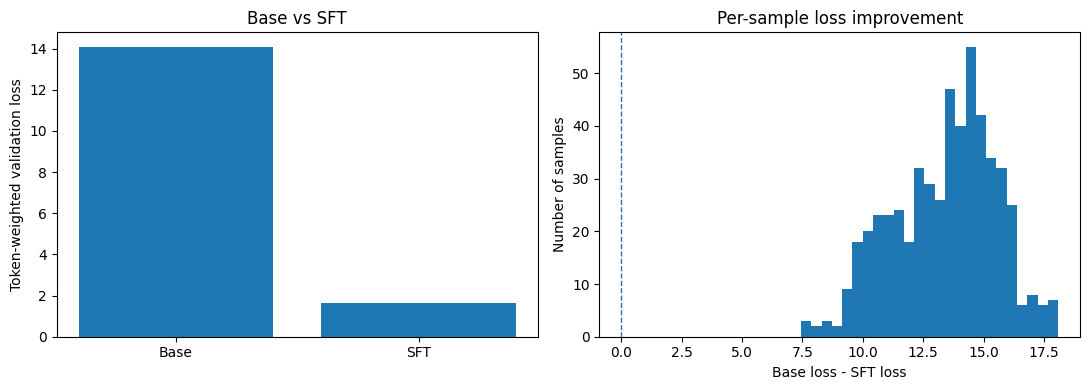

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(["Base", "SFT"], [base_weighted, sft_weighted])
axes[0].set_ylabel("Token-weighted validation loss")
axes[0].set_title("Base vs SFT")

axes[1].hist(df_eval["improvement"], bins=25)
axes[1].axvline(0, linestyle="--", linewidth=1)
axes[1].set_xlabel("Base loss - SFT loss")
axes[1].set_ylabel("Number of samples")
axes[1].set_title("Per-sample loss improvement")
plt.tight_layout()
plt.show()

## 5. 在真实验证轨迹上进行生成对比
直接从验证集 `labels` 的前缀屏蔽位置恢复训练时实际使用的 Prompt Token IDs，无需重新构造 Chat Template，从而避免之前出现过的 `<turn|>` 前缀对齐问题。这里仅生成 Agent 的**下一条回复或工具调用文本**，不会执行 `bash`、`read`、`find` 等工具。

In [7]:
# 从 Token 级验证样本中恢复 Prompt 和目标 Completion
def split_eval_prompt_target(sample):
    ids = sample["input_ids"]
    labels = sample["labels"]
    target_start = next(i for i, lab in enumerate(labels) if lab != -100)
    return ids[:target_start], ids[target_start:]


@torch.inference_mode()
def generate_from_token_ids(model, tokenizer, prompt_ids, use_adapter=True, max_new_tokens=128):
    model.eval()
    device = next(model.parameters()).device
    input_ids = torch.tensor([prompt_ids], dtype=torch.long, device=device)
    attention_mask = torch.ones_like(input_ids)

    kwargs = {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "max_new_tokens": max_new_tokens,
        "do_sample": False,  # 贪心解码，便于公平比较
        "use_cache": True,
        "pad_token_id": tokenizer.pad_token_id or tokenizer.eos_token_id,
    }

    if use_adapter:
        out_ids = model.generate(**kwargs)
    else:
        with model.disable_adapter():
            out_ids = model.generate(**kwargs)

    new_ids = out_ids[0, input_ids.shape[1]:]
    return tokenizer.decode(new_ids, skip_special_tokens=False)


# 从验证集挑选长度适中的几条样本，避免过长 Prompt 占用不必要的生成显存
eligible_indices = [
    i for i, sample in enumerate(eval_dataset)
    if (
        len(sample["input_ids"]) <= 1400
        and 20 <= sum(lab != -100 for lab in sample["labels"]) <= 256
    )
]
# 按长度排序并覆盖短/中/长三个位置，尽量避免只观察最短的样本
eligible_indices.sort(key=lambda i: len(eval_dataset[i]["input_ids"]))
if eligible_indices:
    positions = np.linspace(0, len(eligible_indices) - 1, min(GENERATION_COUNT, len(eligible_indices)))
    generation_indices = list(dict.fromkeys(eligible_indices[int(round(p))] for p in positions))
else:
    generation_indices = []

validation_generations = []
for idx in generation_indices:
    prompt_ids, target_ids = split_eval_prompt_target(eval_dataset[idx])
    base_text = generate_from_token_ids(model, tokenizer, prompt_ids, use_adapter=False, max_new_tokens=MAX_NEW_TOKENS)
    sft_text = generate_from_token_ids(model, tokenizer, prompt_ids, use_adapter=True, max_new_tokens=MAX_NEW_TOKENS)
    target_text = tokenizer.decode(target_ids, skip_special_tokens=False)

    validation_generations.append({
        "index": idx,
        "prompt_tokens": len(prompt_ids),
        "target": target_text,
        "base_response": base_text,
        "sft_response": sft_text,
    })

    print(f"\n========== 验证样本 {idx}（Prompt {len(prompt_ids)} Tokens） ==========")
    print("【真实 Target】\n", target_text[:1500])
    print("【Base】\n", base_text)
    print("【SFT】\n", sft_text)

print("完成真实验证轨迹对比:", len(validation_generations), "条")

The following generation flags are not valid and may be ignored: ['top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



========== 验证样本 168（Prompt 734 Tokens） ==========
【真实 Target】
 Glad to help! Let me know if you want me to dig deeper into any aspect of their implementation.<turn|>

【Base】
 How can I help you today?<turn|>
【SFT】
 Let me know what you'd like to do next! I can help you with:

- **Code changes** (writing, editing, running tests)
- **Understanding code** (explaining concepts or functions)
- **Debugging**
- **Project structure**
- **Finding information**

Just give me a task! 😊<turn|>

========== 验证样本 189（Prompt 895 Tokens） ==========
【真实 Target】
 That assumption does not hold for some OpenAI compatible streams. Ollama can emit a delta with both content and reasoning in the same chunk. The stream handler needs to define a deterministic ordering for mixed deltas or buffer one of the fields. The simplest rule is handle reasoning first, then content. Another option is to treat a mixed delta as a signal to keep the current block type and queue the other field until the block type changes.<tu

## 6. 使用自定义 Agent Prompt 比较工具调用行为
为了与训练时的推理格式保持一致，这里复制训练 Notebook 第 5 节的 **8 种 Agent 工具定义**，使用相同的 `add_generation_prompt=True` 与 `enable_thinking=False`。工具定义只是用于提示模型；本 Notebook **不会实际执行这些工具**。

In [8]:
from typing import Any

# Agent工具定义
KNOWN_TOOL_SCHEMAS: dict[str, dict[str, Any]] = {
    "bash": {
        "description": "Run a shell command in the workspace.",
        "parameters": {
            "type": "object",
            "properties": {
                "command": {"type": "string", "description": "Shell command to run."},
                "cmd": {"type": "string", "description": "Shell command to run."},
                "timeout": {"type": "number", "description": "Optional timeout in milliseconds."},
            },
            "required": [],
        },
    },
    "read": {
        "description": "Read a file or image from the workspace.",
        "parameters": {
            "type": "object",
            "properties": {
                "path": {"type": "string", "description": "Path to read."},
                "file": {"type": "string", "description": "Path to read."},
                "offset": {"type": "number", "description": "Optional starting line."},
                "limit": {"type": "number", "description": "Optional line limit."},
                "start": {"type": "number", "description": "Optional starting line."},
                "end": {"type": "number", "description": "Optional ending line."},
            },
            "required": [],
        },
    },
    "edit": {
        "description": "Edit a file in the workspace.",
        "parameters": {
            "type": "object",
            "properties": {
                "path": {"type": "string", "description": "Path to edit."},
                "oldText": {"type": "string", "description": "Text to replace."},
                "newText": {"type": "string", "description": "Replacement text."},
                "edits": {"type": "array", "description": "Structured edits."},
                "patch": {"type": "string", "description": "Patch content."},
            },
            "required": [],
        },
    },
    "write": {
        "description": "Write content to a file in the workspace.",
        "parameters": {
            "type": "object",
            "properties": {
                "path": {"type": "string", "description": "Path to write."},
                "content": {"type": "string", "description": "File content."},
            },
            "required": [],
        },
    },
    "grep": {
        "description": "Search text in files.",
        "parameters": {
            "type": "object",
            "properties": {
                "pattern": {"type": "string", "description": "Search pattern."},
                "path": {"type": "string", "description": "Path to search."},
                "limit": {"type": "number", "description": "Optional result limit."},
                "literal": {"type": "boolean", "description": "Treat pattern literally."},
                "context": {"type": "number", "description": "Context lines."},
            },
            "required": [],
        },
    },
    "find": {
        "description": "Find files or text in the workspace.",
        "parameters": {
            "type": "object",
            "properties": {
                "pattern": {"type": "string", "description": "Pattern to find."},
                "path": {"type": "string", "description": "Path to search."},
                "limit": {"type": "number", "description": "Optional result limit."},
            },
            "required": [],
        },
    },
    "ls": {
        "description": "List files in a directory.",
        "parameters": {
            "type": "object",
            "properties": {
                "path": {"type": "string", "description": "Directory path."},
                "limit": {"type": "number", "description": "Optional result limit."},
            },
            "required": [],
        },
    },
    "todo": {
        "description": "Manage a lightweight task list.",
        "parameters": {
            "type": "object",
            "properties": {
                "action": {"type": "string", "description": "Task-list action."},
                "text": {"type": "string", "description": "Task text."},
                "id": {"type": "string", "description": "Task identifier."},
            },
            "required": [],
        },
    },
}

In [9]:
# 生成默认工具定义
def generic_tool_schema(name: str) -> dict[str, Any]:
    return {
        "description": f"Pi coding-agent tool named {name}.",
        "parameters": {
            "type": "object",
            "properties": {},
            "required": [],
        },
    }

# 生成工具列表
def make_tool_definitions(tool_names: set[str]) -> list[dict[str, Any]]:
    tools: list[dict[str, Any]] = []
    for name in sorted(n for n in tool_names if n):
        schema = KNOWN_TOOL_SCHEMAS.get(name, generic_tool_schema(name))
        tools.append({"type": "function", "function": {"name": name, **schema}})
    return tools

TOOLS = make_tool_definitions(set(KNOWN_TOOL_SCHEMAS))
print("可用工具:", [tool["function"]["name"] for tool in TOOLS])

可用工具: ['bash', 'edit', 'find', 'grep', 'ls', 'read', 'todo', 'write']


In [10]:
# 使用同一 Chat Template 将消息转换成 Tensor，分别关闭/开启 Adapter
@torch.inference_mode()
def generate_from_messages(model, tokenizer, messages, tools, use_adapter=True, max_new_tokens=128):
    encoded = tokenizer.apply_chat_template(
        messages,
        tools=tools,
        tokenize=True,
        add_generation_prompt=True,
        enable_thinking=False,
        return_tensors="pt",
        return_dict=True,
    )
    device = next(model.parameters()).device
    input_ids = encoded["input_ids"].to(device)
    mask = encoded.get("attention_mask")
    attention_mask = mask.to(device) if mask is not None else torch.ones_like(input_ids)

    kwargs = {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "max_new_tokens": max_new_tokens,
        "do_sample": False,
        "use_cache": True,
        "pad_token_id": tokenizer.pad_token_id or tokenizer.eos_token_id,
    }
    if use_adapter:
        output_ids = model.generate(**kwargs)
    else:
        with model.disable_adapter():
            output_ids = model.generate(**kwargs)

    return tokenizer.decode(output_ids[0, input_ids.shape[1]:], skip_special_tokens=False)


manual_test_cases = [
    {
        "name": "定位代码位置",
        "messages": [{
            "role": "user",
            "content": "Find the function responsible for loading session data in this repository. Inspect the code before explaining it. Do not modify any files.",
        }],
    },
    {
        "name": "查找配置文件",
        "messages": [{
            "role": "user",
            "content": "Locate the project's configuration files and read the most relevant one before suggesting a change. Do not edit any files.",
        }],
    },
]

manual_generations = []
for case in manual_test_cases:
    base_text = generate_from_messages(model, tokenizer, case["messages"], TOOLS, False, MAX_NEW_TOKENS)
    sft_text = generate_from_messages(model, tokenizer, case["messages"], TOOLS, True, MAX_NEW_TOKENS)
    manual_generations.append({
        "name": case["name"],
        "messages": case["messages"],
        "base_response": base_text,
        "sft_response": sft_text,
    })
    print(f"\n========== {case['name']} ==========")
    print("【Base】\n", base_text)
    print("【SFT】\n", sft_text)

# 注意：输出 <|tool_call>... 只是模型提议的工具调用，并不代表工具已执行


========== 定位代码位置 ==========
【Base】
 <|tool_call>call:find{pattern:<|"|>load session data<|"|>}<tool_call|><|tool_response>
【SFT】
 <|tool_call>call:find{pattern:<|"|>loadSessionData<|"|>}<tool_call|><|tool_response>

========== 查找配置文件 ==========
【Base】
 <|tool_call>call:ls{path:<|"|>.<|"|>}<tool_call|><|tool_response>
【SFT】
 <|tool_call>call:ls{path:<|"|>.<|"|>}<tool_call|><|tool_response>


## 7. 保存评估结果
分别保存逐样本 Loss、汇总指标、真实验证轨迹生成结果以及自定义 Prompt 的 Base/SFT 对比，方便后续比较不同 LoRA Rank、目标层和训练轮次。

In [11]:
EVAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 单条验证样本的交叉熵损失
df_eval.to_csv(EVAL_OUTPUT_DIR / "validation_loss_comparison.csv", index=False)

# 汇总指标
(EVAL_OUTPUT_DIR / "evaluation_summary.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8"
)

# 生成对比
(EVAL_OUTPUT_DIR / "validation_generation_comparison.json").write_text(
    json.dumps(validation_generations, indent=2, ensure_ascii=False), encoding="utf-8"
)
(EVAL_OUTPUT_DIR / "manual_generation_comparison.json").write_text(
    json.dumps(manual_generations, indent=2, ensure_ascii=False), encoding="utf-8"
)

print("评估结果保存到:", EVAL_OUTPUT_DIR)
for path in sorted(EVAL_OUTPUT_DIR.iterdir()):
    print(" -", path.name)

评估结果保存到: sft-output/gemma4-e2b-lora-full/evaluation
 - evaluation_summary.json
 - manual_generation_comparison.json
 - validation_generation_comparison.json
 - validation_loss_comparison.csv
